# RetailIQ: Data Exploration & Visualization

**Project**: E-commerce Customer Purchase Prediction  
**Dataset**: 2.7M e-commerce events  
**Goal**: Understand the data and visualize patterns

## 1. Setup
Import libraries and initialize Spark

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, when, hour, from_unixtime
import matplotlib.pyplot as plt
import pandas as pd

# Start Spark
spark = SparkSession.builder \
    .appName("RetailIQ_DataExploration") \
    .master("local[*]") \
    .getOrCreate()

print("✓ Spark initialized")

26/10/17 13:16:17 WARN Utils: Your hostname, Kireetis-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 10.12.112.156 instead (on interface en0)
26/10/17 13:16:17 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/17 13:16:18 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/17 13:16:20 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/10/17 13:16:20 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.


✓ Spark initialized


## 2. Load Dataset

In [2]:
# Load data
df = spark.read \
    .option("header", True) \
    .option("inferSchema", True) \
    .csv("../data/events.csv")

print(f"Total Records: {df.count():,}")
print(f"\nColumns: {df.columns}")

26/10/17 13:16:32 WARN GarbageCollectionMetrics: To enable non-built-in garbage collector(s) List(G1 Concurrent GC), users should configure it(them) to spark.eventLog.gcMetrics.youngGenerationGarbageCollectors or spark.eventLog.gcMetrics.oldGenerationGarbageCollectors


Total Records: 2,756,101

Columns: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


## 3. Data Overview

In [3]:
# Show sample data
df.show(10)

+-------------+---------+-----+------+-------------+
|    timestamp|visitorid|event|itemid|transactionid|
+-------------+---------+-----+------+-------------+
|1433221332117|   257597| view|355908|         NULL|
|1433224214164|   992329| view|248676|         NULL|
|1433221999827|   111016| view|318965|         NULL|
|1433221955914|   483717| view|253185|         NULL|
|1433221337106|   951259| view|367447|         NULL|
|1433224086234|   972639| view| 22556|         NULL|
|1433221923240|   810725| view|443030|         NULL|
|1433223291897|   794181| view|439202|         NULL|
|1433220899221|   824915| view|428805|         NULL|
|1433221204592|   339335| view| 82389|         NULL|
+-------------+---------+-----+------+-------------+
only showing top 10 rows



In [4]:
# Data schema
df.printSchema()

root
 |-- timestamp: long (nullable = true)
 |-- visitorid: integer (nullable = true)
 |-- event: string (nullable = true)
 |-- itemid: integer (nullable = true)
 |-- transactionid: integer (nullable = true)



## 4. Event Distribution

In [5]:
# Count events by type
event_counts = df.groupBy("event") \
    .count() \
    .orderBy("count", ascending=False) \
    .toPandas()

print("Event Counts:")
print(event_counts)

Event Counts:
         event    count
0         view  2664312
1    addtocart    69332
2  transaction    22457


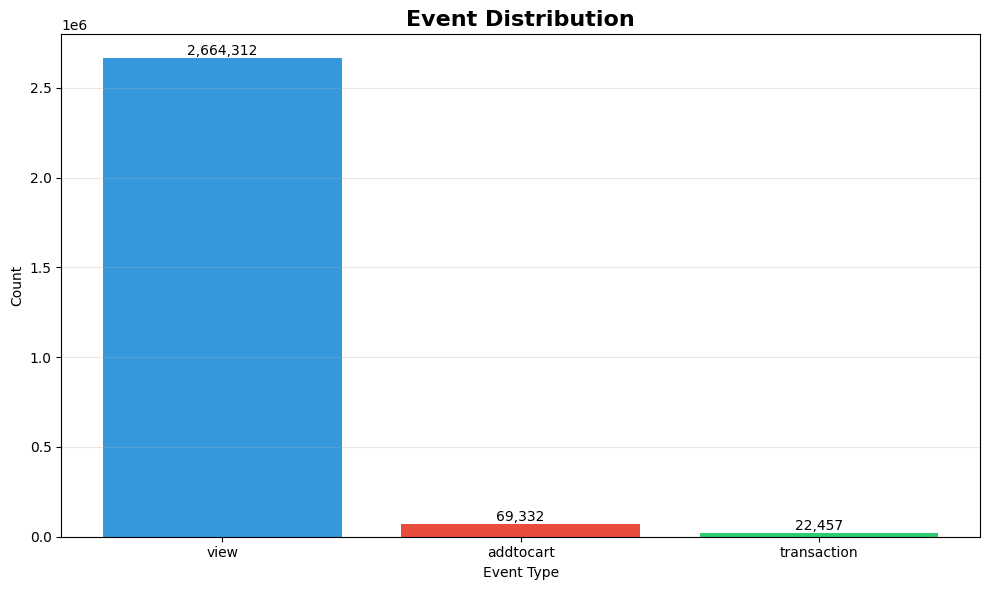

In [6]:
# Visualize event distribution
plt.figure(figsize=(10, 6))
plt.bar(event_counts['event'], event_counts['count'], color=['#3498db', '#e74c3c', '#2ecc71'])
plt.title('Event Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Event Type')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.3)

# Add count labels
for i, v in enumerate(event_counts['count']):
    plt.text(i, v, f'{v:,}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

## 5. Visitor Engagement

In [7]:
# Events per visitor
visitor_events = df.groupBy("visitorid").agg(count("*").alias("event_count"))

# Categorize engagement
engagement = visitor_events.withColumn(
    "category",
    when(col("event_count") == 1, "1 event")
    .when(col("event_count") <= 5, "2-5 events")
    .when(col("event_count") <= 10, "6-10 events")
    .when(col("event_count") <= 20, "11-20 events")
    .otherwise("20+ events")
)

engagement_counts = engagement.groupBy("category").count().toPandas()
print(engagement_counts)

       category    count
0    2-5 events   347367
1       1 event  1001560
2   6-10 events    39071
3    20+ events     6057
4  11-20 events    13525


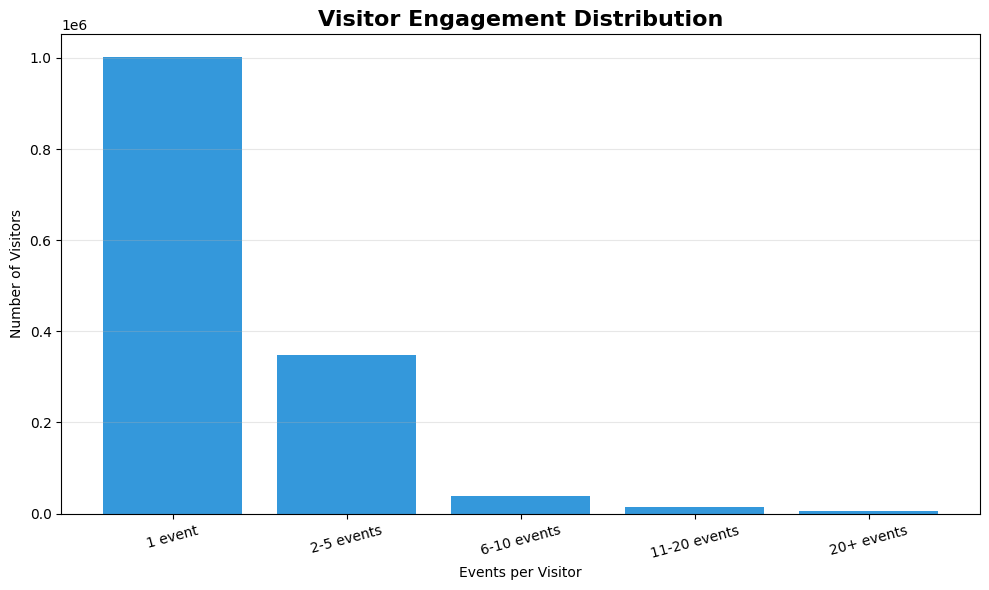

In [8]:
# Visualize engagement
categories = ["1 event", "2-5 events", "6-10 events", "11-20 events", "20+ events"]
engagement_counts = engagement_counts.set_index('category').reindex(categories).reset_index()

plt.figure(figsize=(10, 6))
plt.bar(engagement_counts['category'], engagement_counts['count'], color='#3498db')
plt.title('Visitor Engagement Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Events per Visitor')
plt.ylabel('Number of Visitors')
plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Hourly Activity Pattern

In [9]:
# Extract hour from timestamp
hourly_df = df.withColumn("hour", hour(from_unixtime(col("timestamp") / 1000)))

hourly_counts = hourly_df.groupBy("hour") \
    .count() \
    .orderBy("hour") \
    .toPandas()

print("Hourly Activity:")
print(hourly_counts.head(10))

Hourly Activity:
   hour   count
0     0  181444
1     1  186163
2     2  186821
3     3  180913
4     4  168257
5     5  151210
6     6  141481
7     7  142286
8     8  148576
9     9  151716


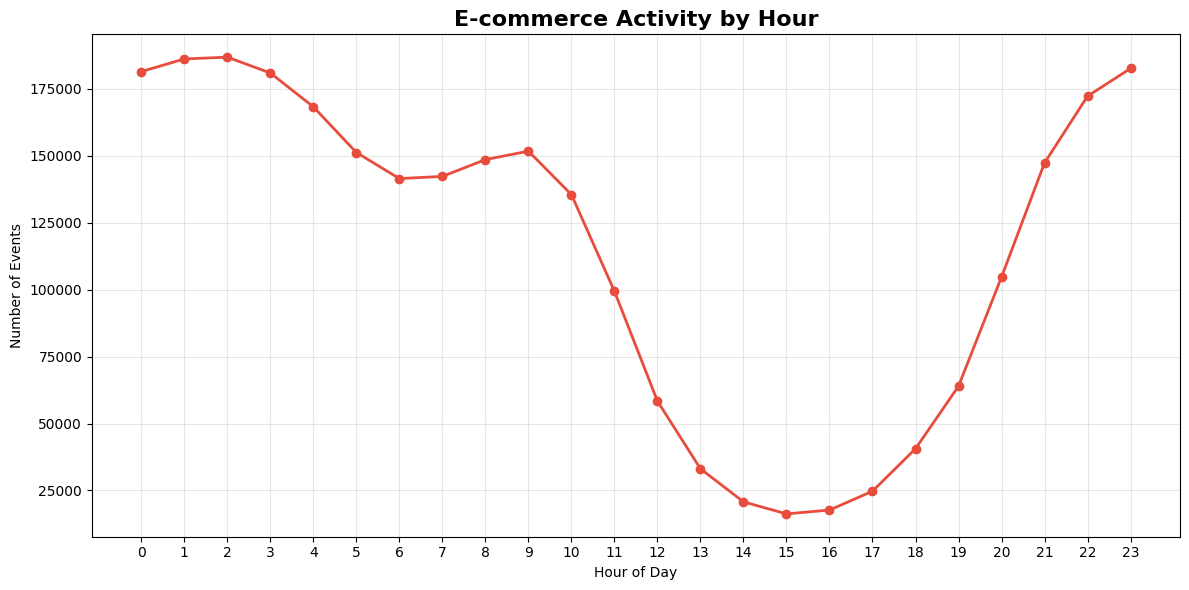

In [10]:
# Visualize hourly pattern
plt.figure(figsize=(12, 6))
plt.plot(hourly_counts['hour'], hourly_counts['count'], marker='o', linewidth=2, color='#e74c3c')
plt.title('E-commerce Activity by Hour', fontsize=16, fontweight='bold')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Events')
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Top Products

In [11]:
# Top viewed products
top_viewed = df.filter(col("event") == "view") \
    .groupBy("itemid") \
    .count() \
    .orderBy("count", ascending=False) \
    .limit(10) \
    .toPandas()

print("Top 10 Viewed Products:")
print(top_viewed)

Top 10 Viewed Products:
   itemid  count
0  187946   3410
1  461686   2539
2    5411   2325
3  370653   1854
4  219512   1740
5  298009   1642
6   96924   1633
7  309778   1565
8  257040   1531
9  384302   1528


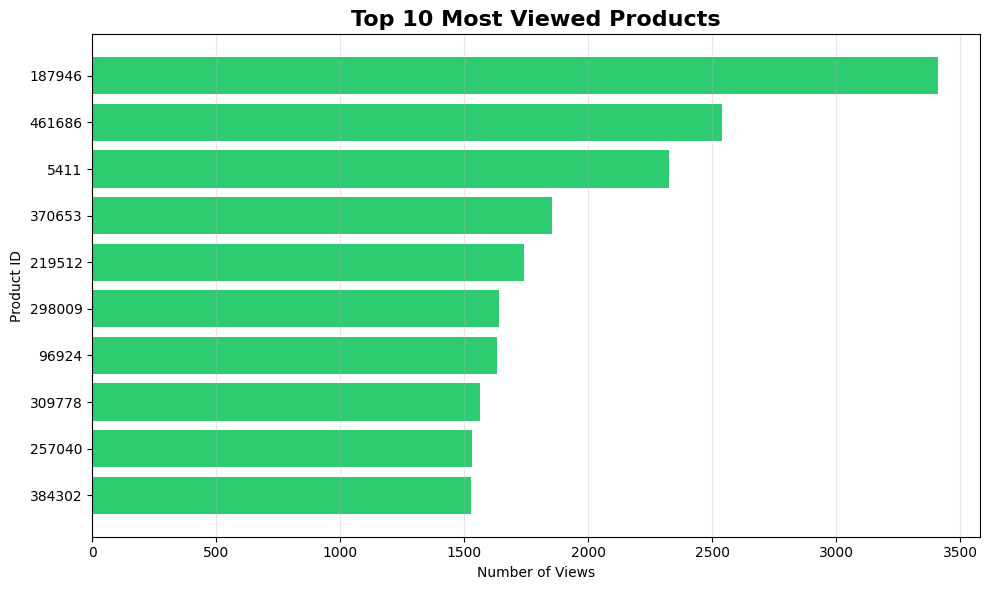

In [12]:
# Visualize top products
plt.figure(figsize=(10, 6))
plt.barh(top_viewed['itemid'].astype(str), top_viewed['count'], color='#2ecc71')
plt.gca().invert_yaxis()
plt.title('Top 10 Most Viewed Products', fontsize=16, fontweight='bold')
plt.xlabel('Number of Views')
plt.ylabel('Product ID')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Summary Statistics

In [13]:

print("DATASET SUMMARY")

print(f"Total Events: {df.count():,}")
print(f"Unique Visitors: {df.select('visitorid').distinct().count():,}")
print(f"Unique Products: {df.select('itemid').distinct().count():,}")
print(f"Event Types: {df.select('event').distinct().count()}")


DATASET SUMMARY


Total Events: 2,756,101


Unique Visitors: 1,407,580


Unique Products: 235,061


Event Types: 3


## 9. Stop Spark

In [14]:
spark.stop()
print("✓ Spark stopped")

✓ Spark stopped


---
## Key Insights

1. **Most events are views** - customers browse a lot
2. **Few transactions** - low conversion rate
3. **Peak activity hours** - can identify best times for marketing
4. **Popular products** - can focus inventory on these items
5. **Visitor engagement varies** - some visit once, others are very engaged

**Next**: Build ML models to predict which visitors will make purchases!